# Stroke Generation Model

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import Optional, Tuple, Sequence, List, Dict, Any
import os
import yaml

from dataclasses import dataclass, field
from scipy.special import erf
import torch
import torch.nn as nn
from torch.nn.init import xavier_uniform
import torch.nn.functional as F
from torch.distributions import Categorical, MultivariateNormal
from torch.utils.data import Dataset, DataLoader

## Stroke

In [2]:
STROKE_TIME_COLS = ['mu', 'sigma', 't0']
STROKE_GEOM_COLS = ['delta_p', 'u_e', 'lambda_e', 'u_s', 'lambda_s']
ARRAY_COLS = ['delta_p', 'u_s', 'u_e']
DATABASE_ROOT = os.getcwd().split('src')[0] + 'reconstructed_csv'
EPS = 1e-12


# ---- network I/O definition ----
# Outputs of the stroke network. Every stroke is expressed from its own origin: it starts at zero.
TARGET_KEYS = ["t0", "mu", "sigma", "lambda_e", "u_e", "delta_p"]
# Previous-stroke input = every target EXCEPT delta_p (a stroke never knows where the previous one ended).
PREV_KEYS = [f"prev_{k}" for k in TARGET_KEYS if k != "delta_p"]
# u_s / lambda_s are NOT outputs of the stroke network: they are drawn once for the first stroke,
# then every stroke inherits the end tangent of the previous one (C1 junction of the Bezier chain).

GEOM_SHARED_KEYS = ("wp", "wp_n", "delta_p")        # same zero-mean isotropic scale (see compute_stats)
STAT_KEYS = ["wp", "wp_n"] + TARGET_KEYS
DATASET_KEYS = ["wp", "wp_n", "is_first", "u_s", "lambda_s"] + TARGET_KEYS + PREV_KEYS

## Nework Architecture

### Mixture Density Network Head

In [3]:

class MixtureDensityNetwork(nn.Module):
    """
    MDN head with full-covariance Gaussian components.
    Outputs: means [B, K, D], lower Cholesky factors [B, K, D, D], mixing logits [B, K].
    """

    def __init__(self, input_dim, output_dim, num_components, hidden_dim=128, min_diag=1e-3):
        super().__init__()
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.num_components = num_components
        self.hidden_dim = hidden_dim
        self.min_diag = min_diag
        self.num_tril = output_dim * (output_dim + 1) // 2

        rows, cols = torch.tril_indices(output_dim, output_dim)
        self.register_buffer("tril_rows", rows, persistent=False)
        self.register_buffer("tril_cols", cols, persistent=False)
        self.register_buffer("diag_mask", rows == cols, persistent=False)

        self.hidden_layer = nn.Linear(input_dim, hidden_dim)
        self.weights_layer = nn.Linear(hidden_dim, num_components)  # mixing logits
        self.means_layer = nn.Linear(hidden_dim, num_components * output_dim)
        self.scale_layer = nn.Linear(hidden_dim, num_components * self.num_tril)

    def set_weights(self, target_samples: torch.Tensor, sigma_weight_scale: float = 0.1):
        """
        Initialization. `target_samples` [N, D] should already be standardized.
        Means are spread over the target range; each Cholesky factor starts as
        diag(std_d) with zero off-diagonal entries.
        """
        nn.init.kaiming_uniform_(self.hidden_layer.weight, nonlinearity="relu")
        nn.init.zeros_(self.hidden_layer.bias)

        nn.init.xavier_uniform_(self.weights_layer.weight)
        nn.init.xavier_uniform_(self.means_layer.weight)
        nn.init.xavier_uniform_(self.scale_layer.weight)

        t_min = target_samples.min(dim=0).values  # [D]
        t_max = target_samples.max(dim=0).values  # [D]
        mean_bias = torch.empty(self.num_components, self.output_dim)
        for k in range(self.num_components):
            mean_bias[k] = (t_min + (t_max - t_min) * (k + 0.5) / self.num_components).cpu()

        with torch.no_grad():
            self.means_layer.bias.copy_(mean_bias.reshape(-1))
            self.scale_layer.weight.mul_(sigma_weight_scale)

            # inverse softplus so that diag(L) starts at the per-dimension data std
            data_std = target_samples.std(dim=0).to(self.scale_layer.bias)
            init_diag = (data_std - self.min_diag).clamp_min(1e-3)
            raw_diag = torch.log(torch.expm1(init_diag))
            bias = torch.zeros(self.num_components, self.num_tril).to(self.scale_layer.bias)
            bias[:, self.diag_mask] = raw_diag
            self.scale_layer.bias.copy_(bias.reshape(-1))

    def _build_scale_tril(self, raw: torch.Tensor) -> torch.Tensor:
        """raw [B, K, m] -> lower-triangular L [B, K, D, D] with positive diagonal."""
        batch = raw.size(0)
        dim = self.output_dim
        tril = raw.new_zeros(batch, self.num_components, dim, dim)
        tril[..., self.tril_rows, self.tril_cols] = raw
        diag = F.softplus(tril.diagonal(dim1=-2, dim2=-1)) + self.min_diag
        return tril.tril(-1) + torch.diag_embed(diag)

    def forward(self, x: torch.Tensor):
        hidden = torch.relu(self.hidden_layer(x))
        mix_logits = self.weights_layer(hidden)
        means = self.means_layer(hidden).view(-1, self.num_components, self.output_dim)
        raw = self.scale_layer(hidden).view(-1, self.num_components, self.num_tril)
        return means, self._build_scale_tril(raw), mix_logits

### Full Model Architecture

In [4]:
class GenerativeModel(nn.Module):
    """Generative model of strokes: embeddings -> LSTM -> trunk -> full-covariance MDN."""

    def __init__(self, input_dim, embedding_dim, LSTM_dim, LSTM_count, output_dim,
                 mixture_components, recur_dim=None, min_diag=1e-3):
        super().__init__()
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.embedding_dim = embedding_dim
        self.lstm_dim = LSTM_dim
        self.lstm_count = LSTM_count
        self.mixture_components = mixture_components
        # dimension of the previous-step vector (defaults to the target dimension)
        self.recur_dim = output_dim if recur_dim is None else recur_dim

        self.input_embedding = nn.Linear(input_dim, embedding_dim)
        self.recur_embedding = nn.Linear(self.recur_dim, embedding_dim)
        self.lstm = nn.LSTM(input_size=embedding_dim * 2, hidden_size=LSTM_dim,
                            num_layers=LSTM_count, batch_first=True)
        self.trunk = nn.Linear(LSTM_dim, LSTM_dim)
        self.mdn = MixtureDensityNetwork(LSTM_dim, output_dim,
                                         num_components=mixture_components, min_diag=min_diag)

    def set_weights(self, target_samples, sigma_weight_scale=0.1):
        self.mdn.set_weights(target_samples, sigma_weight_scale)
        for layer in (self.input_embedding, self.recur_embedding, self.trunk):
            nn.init.kaiming_uniform_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)

    def forward(self, x, prev_output=None, state=None, return_state=False):
        """
        Args:
            x: conditioning input [B, input_dim]
            prev_output: previous-step vector [B, recur_dim] (zeros embedding if None)
            state: optional LSTM state (h, c) carried across calls; None resets it
        Returns:
            means [B, K, D], scale_tril [B, K, D, D], mix_logits [B, K] (+ state if requested)
        """
        input_embedded = self.input_embedding(x)
        if prev_output is not None:
            prev_embedded = self.recur_embedding(prev_output)
        else:
            prev_embedded = torch.zeros_like(input_embedded)

        combined = torch.cat((input_embedded, prev_embedded), dim=-1)
        lstm_out, new_state = self.lstm(combined.unsqueeze(1), state)  # sequence length 1
        trunk_out = torch.relu(self.trunk(lstm_out.squeeze(1)))

        means, scale_tril, mix_logits = self.mdn(trunk_out)
        if return_state:
            return means, scale_tril, mix_logits, new_state
        return means, scale_tril, mix_logits

    @torch.no_grad()
    def sample(self, x, prev_output=None, state=None):
        means, scale_tril, mix_logits = self.forward(x, prev_output, state)
        batch_idx = torch.arange(means.size(0), device=means.device)
        comp_idx = Categorical(logits=mix_logits).sample()
        sel_mean = means[batch_idx, comp_idx]          # [B, D]
        sel_tril = scale_tril[batch_idx, comp_idx]     # [B, D, D]
        eps = torch.randn_like(sel_mean)
        return sel_mean + (sel_tril @ eps.unsqueeze(-1)).squeeze(-1)



## Loss

In [5]:
def duplication_matrix(dim: int, device=None, dtype=None) -> torch.Tensor:
    """
    Duplication matrix Dup such that vec(S) = Dup @ vech(S) for any symmetric S.
    Shape: [dim * dim, dim * (dim + 1) // 2]. Row-major vec, lower-triangle vech.
    """
    rows, cols = torch.tril_indices(dim, dim, device=device)
    n_free = rows.numel()
    dup = torch.zeros(dim * dim, n_free, device=device, dtype=dtype)
    col_idx = torch.arange(n_free, device=device)
    dup[rows * dim + cols, col_idx] = 1.0
    dup[cols * dim + rows, col_idx] = 1.0
    return dup


def gaussian_fisher(sigma: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Explicit Fisher information blocks of N(mu, Sigma).

    Args:
        sigma: covariance matrices, shape [..., D, D].
    Returns:
        fisher_mu:    [..., D, D]   = Sigma^-1
        fisher_sigma: [..., m, m]   = 1/2 Dup^T (Sigma^-1 (x) Sigma^-1) Dup, m = D(D+1)/2
    """
    dim = sigma.size(-1)
    dup = duplication_matrix(dim, sigma.device, sigma.dtype)
    sigma_inv = torch.linalg.inv(sigma)
    kron = torch.einsum("...ij,...kl->...ikjl", sigma_inv, sigma_inv)
    kron = kron.reshape(*sigma.shape[:-2], dim * dim, dim * dim)
    fisher_sigma = 0.5 * dup.T @ kron @ dup
    return sigma_inv, fisher_sigma


def gaussian_fisher_matrix(sigma: torch.Tensor) -> torch.Tensor:
    """Full block-diagonal Fisher matrix over (mu, vech(Sigma)), shape [..., D+m, D+m]."""
    fisher_mu, fisher_sigma = gaussian_fisher(sigma)
    dim, n_free = fisher_mu.size(-1), fisher_sigma.size(-1)
    full = sigma.new_zeros(*sigma.shape[:-2], dim + n_free, dim + n_free)
    full[..., :dim, :dim] = fisher_mu
    full[..., dim:, dim:] = fisher_sigma
    return full


def gaussian_natural_gradient(
    diff: torch.Tensor,
    sigma: torch.Tensor,
    resp: torch.Tensor,
    explicit_fisher: bool = False,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Complete-data natural gradient of resp * log N(y; mu, Sigma) w.r.t. (mu, vech(Sigma)).

    Args:
        diff:  y - mu, shape [..., D]
        sigma: covariance, shape [..., D, D]
        resp:  responsibilities, shape [...]
        explicit_fisher: if True, build the Fisher blocks explicitly and solve F x = grad
            (O(D^6) per component: use it to validate, not for training).
            If False, use the equivalent closed form.
    Returns:
        nat_mu:    [..., D]
        nat_sigma: [..., m]  (vech coordinates)
    """
    dim = diff.size(-1)
    rows, cols = torch.tril_indices(dim, dim, device=diff.device)
    outer = diff.unsqueeze(-1) * diff.unsqueeze(-2)  # d d^T

    if not explicit_fisher:
        nat_mu = resp.unsqueeze(-1) * diff
        nat_sigma = resp[..., None, None] * (outer - sigma)
        return nat_mu, nat_sigma[..., rows, cols]

    fisher_mu, fisher_sigma = gaussian_fisher(sigma)
    sigma_inv = fisher_mu
    dup = duplication_matrix(dim, diff.device, diff.dtype)

    grad_mu = resp.unsqueeze(-1) * (sigma_inv @ diff.unsqueeze(-1)).squeeze(-1)
    # symmetric matrix derivative of resp * log N w.r.t. Sigma
    grad_mat = 0.5 * resp[..., None, None] * (sigma_inv @ outer @ sigma_inv - sigma_inv)
    grad_vech = torch.einsum("pm,...p->...m", dup, grad_mat.reshape(*sigma.shape[:-2], dim * dim))

    nat_mu = torch.linalg.solve(fisher_mu, grad_mu.unsqueeze(-1)).squeeze(-1)
    nat_sigma = torch.linalg.solve(fisher_sigma, grad_vech.unsqueeze(-1)).squeeze(-1)
    return nat_mu, nat_sigma


def categorical_natural_gradient(
    resp: torch.Tensor, pi: torch.Tensor, pi_floor: float = 1e-4
) -> torch.Tensor:
    """
    Natural gradient of sum_k r_k log pi_k w.r.t. the softmax logits.
    The Fisher matrix diag(pi) - pi pi^T is singular; r / pi solves F x = r - pi, and the
    mean is removed (softmax is invariant to a constant shift of the logits).
    `pi_floor` avoids huge steps when a component has a vanishing weight.
    """
    ratio = resp / pi.clamp_min(pi_floor)
    return ratio - ratio.mean(dim=-1, keepdim=True)

In [6]:
def model_io(batch, device):
    """Normalized batch -> (conditioning x, previous-stroke input, target)."""
    x = torch.cat([batch["wp"], batch["wp_n"], batch["is_first"]], dim=-1).to(device)
    prev = torch.cat([batch[k] for k in PREV_KEYS], dim=-1).to(device)
    target = torch.cat([batch[k] for k in TARGET_KEYS], dim=-1).to(device)
    return x, prev, target


def mixture_nll(means, scale_tril, logits, target):
    """Mean negative log-likelihood of `target` [B, D] under the mixture (means [B,K,D], L [B,K,D,D], logits [B,K])."""
    log_prob = MultivariateNormal(means, scale_tril=scale_tril).log_prob(target.unsqueeze(1))
    return -torch.logsumexp(F.log_softmax(logits, dim=-1) + log_prob, dim=-1).mean()


def mdn_nll_loss(model, batch, device, return_nll=True, **_):
    """Plain mixture NLL (same call signature as ngem_loss)."""
    x, prev, target = model_io(batch, device)
    means, scale_tril, logits = model(x, prev_output=prev)
    nll = mixture_nll(means, scale_tril, logits, target)
    return nll, nll.detach()

In [7]:
def ngem_loss(
    model,
    batch,
    device,
    fisher_mode: str = "closed_form",
    natural_mixing: bool = True,
    pi_floor: float = 1e-4,
    return_nll: bool = False,
):
    """
    Multivariate (full covariance) nGEM surrogate loss.

    E-step: responsibilities from the current parameters (no gradient).
    M-step: the complete-data natural gradient w.r.t. the network outputs
            (means, vech(Sigma), mixing logits) is computed with the Fisher blocks of
            each component and injected into backprop through a surrogate loss, so that
            d(loss)/d(output) = -natural_gradient / batch_size.

    Args:
        fisher_mode: "closed_form" (fast) or "explicit" (builds and solves the Fisher
            blocks; use it for validation).
        natural_mixing: natural gradient for the mixing logits (True) or plain gradient
            r - pi (False).
        pi_floor: lower clamp on pi in the categorical natural gradient.
        return_nll: also return the mixture NLL (detached) for monitoring.
    """
    if fisher_mode not in ("closed_form", "explicit"):
        raise ValueError("fisher_mode must be 'closed_form' or 'explicit'")

    input_data, prev_input, target = model_io(batch, device)
    means, scale_tril, mix_logits = model(input_data, prev_output=prev_input)
    batch_size, dim = target.shape

    # ---- E-step (no gradient) ----
    with torch.no_grad():
        dist = MultivariateNormal(loc=means.detach(), scale_tril=scale_tril.detach())
        log_prob = dist.log_prob(target.unsqueeze(1))                  # [B, K]
        log_joint = F.log_softmax(mix_logits.detach(), dim=-1) + log_prob
        resp = torch.softmax(log_joint, dim=-1)                        # [B, K]
        nll = -torch.logsumexp(log_joint, dim=-1).mean()
        pi = torch.softmax(mix_logits.detach(), dim=-1)

    # ---- M-step: natural gradients w.r.t. the network outputs ----
    diff = (target.unsqueeze(1) - means).detach()                      # [B, K, D]
    cov = scale_tril @ scale_tril.transpose(-1, -2)                    # Sigma = L L^T (with grad)
    rows, cols = torch.tril_indices(dim, dim, device=target.device)
    cov_vech = cov[..., rows, cols]                                    # [B, K, m]

    nat_mu, nat_cov = gaussian_natural_gradient(
        diff, cov.detach(), resp, explicit_fisher=(fisher_mode == "explicit")
    )
    nat_pi = categorical_natural_gradient(resp, pi, pi_floor) if natural_mixing else resp - pi

    # Surrogate: its gradient w.r.t. (means, vech(Sigma), logits) is minus the natural
    # gradient; autograd then applies the Jacobian (chain rule) down to the weights.
    # Note: vech coordinates (lower triangle only) are used on purpose, so that the
    # off-diagonal entries of Sigma are not counted twice.
    surrogate = (
        (means * nat_mu).sum()
        + (cov_vech * nat_cov).sum()
        + (mix_logits * nat_pi).sum()
    )
    loss = -surrogate / batch_size

    if return_nll:
        return loss, nll
    return loss

## Dataset
Define the classes

In [8]:
class StrokeDataset(Dataset):
    """
    Stroke data stored as pre-stacked float32 tensors, one [N, d] tensor per key.
    Every item is a dict {key: tensor [d]} (scalars have d = 1).
    """
    def __init__(self, data_frame: pd.DataFrame, keys=DATASET_KEYS):
        n = len(data_frame)
        self.keys = list(keys)
        self.tensors = {}
        for k in self.keys:
            values = np.asarray(data_frame[k].tolist(), dtype=np.float32).reshape(n, -1)
            tensor = torch.from_numpy(values)
            if not torch.isfinite(tensor).all():
                raise ValueError(f"non-finite values in column '{k}'")
            self.tensors[k] = tensor
        self.length = n

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        return {k: v[idx] for k, v in self.tensors.items()}

In [9]:
class StrokeDataLoader(DataLoader):
    """
    A custom DataLoader class for loading stroke data.
    """
    def __init__(self, dataset: StrokeDataset, batch_size: int = 32, shuffle: bool = True, num_workers: int = 0):
        """
        Args:
            dataset (StrokeDataset): The dataset to load.
            batch_size (int): Number of samples per batch.
            shuffle (bool): Whether to shuffle the data at every epoch.
            num_workers (int): How many subprocesses to use for data loading.
        """
        super(StrokeDataLoader, self).__init__(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers)

In [10]:
def create_database(root:str) -> pd.DataFrame:
    """
    Create a database of stroke parameters from CSV files in the given root directory.

    Args:
        root (str): The root directory containing CSV files.
    Returns:
        database (pd.DataFrame): Dafaframe representation of the dataset
    """
    root_folder = os.path.abspath(os.path.join(os.getcwd(), root))
    records = []

    for subject_folder in os.listdir(root_folder):
        if not os.path.isdir(os.path.join(root_folder, subject_folder)):
            continue
        subject_name = os.path.basename(subject_folder)

        for task_folder in os.listdir(os.path.join(root_folder, subject_folder)):
            if not os.path.isdir(os.path.join(root_folder, subject_folder, task_folder)):
                continue
            task_name = os.path.basename(task_folder)

            for csv_file in os.listdir(os.path.join(root_folder, subject_folder, task_folder)):
                if os.path.isdir(os.path.join(root_folder, subject_folder, task_folder, csv_file)):
                    continue
                csv_path = os.path.join(root_folder, subject_folder, task_folder, csv_file)
                recording_number = int(os.path.basename(csv_file).split('_')[1].split('.')[0])  # Assuming the format is 'recording_X.csv'
                stroke_data = pd.read_csv(csv_path)

                for _, row in stroke_data.iterrows():
                    record = {
                        'subject': subject_name,
                        'task': task_name,
                        'recording': recording_number,
                        'stroke_number': int(row['stroke_id']),
                    }
                    for col in STROKE_TIME_COLS + STROKE_GEOM_COLS:
                        record[col] = row[col]

                    for col in ARRAY_COLS:
                        record[col] = [float(x) for x in row[col].split(';')]
                    records.append(record)
            

    subject_names = sorted({record["subject"] for record in records})
    subject_map = {
        name: f"S{index:02d}"
        for index, name in enumerate(subject_names, start=1)
    }

    for record in records:
        record["subject"] = subject_map[record["subject"]]

    return pd.DataFrame(records)
database = create_database(DATABASE_ROOT)


### Data preprocessing
Couple each stroke with its previous one, when available.

In [11]:
coupled_database = database.merge(
    database,
    on=['subject', 'task', 'recording'],
    how='outer',
    suffixes=('', '_previous')
)
coupled_database = coupled_database[
    (coupled_database['stroke_number'] == coupled_database['stroke_number_previous'] + 1)
    | (coupled_database['stroke_number'] == 0)
]
previous_cols = [col for col in coupled_database.columns if col.endswith("_previous")]
coupled_database.loc[coupled_database["stroke_number"].eq(0), previous_cols] = None
# Convert list-like values to hashable tuples before deduplicating.
for col in coupled_database.columns:
    if coupled_database[col].map(lambda v: isinstance(v, (list, tuple, np.ndarray))).any():
        coupled_database[col] = coupled_database[col].map(
            lambda v: tuple(np.asarray(v, dtype=float).ravel().tolist())
            if isinstance(v, (list, tuple, np.ndarray))
            else v
        )

coupled_database = coupled_database.drop_duplicates().reset_index(drop=True)

Extract and compute the $\Delta wp$

In [12]:
PATH_TO_PATHS_FILE = os.path.join(os.getcwd(), '..', '..', '..', 'unisa_acg_ros2', 'haptics', 'haptic_interaction_teach_and_record_demo', 'config', 'paths.yaml')
if not os.path.exists(PATH_TO_PATHS_FILE):
    raise FileNotFoundError(f"Paths file not found: {PATH_TO_PATHS_FILE}")


WS_MIN = np.array([-0.082, -0.065, -0.085])
WS_MAX = np.array([0.082, 0.065, 0.085])

def waypoints_to_array(waypoints, swap_yz=False, ws_min=WS_MIN, ws_max=WS_MAX):
    """Convert the list of {'x','y','z'} dicts (normalized) into an Nx3 array in device coordinates."""
    arr = np.array([[w["x"], w["y"], w["z"]] for w in waypoints], dtype=float)
    if swap_yz:
        arr[:, [1, 2]] = arr[:, [2, 1]]
    if ws_min is not None and ws_max is not None:
        ws_min = np.asarray(ws_min, dtype=float)
        ws_max = np.asarray(ws_max, dtype=float)
        arr = ws_min + arr * (ws_max - ws_min)
    return arr

WAYPOINTS_BY_TASK = {}
with open(PATH_TO_PATHS_FILE, 'r') as f:
    paths_data = yaml.safe_load(f)
    print(f"Loaded paths data: {paths_data['paths']}")

    for path in paths_data['paths']:
        WAYPOINTS_BY_TASK[path['name']] = waypoints_to_array(path['waypoints'])

WAYPOINTS_BY_TASK = {
    task: waypoints - waypoints[0]
    for task, waypoints in WAYPOINTS_BY_TASK.items()
}

WAYPOINTS_BY_TASK

Loaded paths data: [{'name': 'BURSTs_XY', 'waypoints': [{'x': 0.2, 'y': 0.2, 'z': 0.5}, {'x': 0.8, 'y': 0.8, 'z': 0.5}]}, {'name': 'BURSTs_XZ', 'waypoints': [{'x': 0.2, 'y': 0.5, 'z': 0.2}, {'x': 0.8, 'y': 0.5, 'z': 0.8}]}, {'name': 'BURSTs_YZ', 'waypoints': [{'x': 0.5, 'y': 0.2, 'z': 0.2}, {'x': 0.5, 'y': 0.8, 'z': 0.8}]}, {'name': 'BURSTc_XY', 'waypoints': [{'x': 0.1, 'y': 0.2, 'z': 0.5}, {'x': 0.9, 'y': 0.5, 'z': 0.5}, {'x': 0.1, 'y': 0.8, 'z': 0.5}]}, {'name': 'BURSTc_XZ', 'waypoints': [{'x': 0.2, 'y': 0.5, 'z': 0.1}, {'x': 0.5, 'y': 0.5, 'z': 0.9}, {'x': 0.8, 'y': 0.5, 'z': 0.1}]}, {'name': 'BURSTc_YZ', 'waypoints': [{'x': 0.5, 'y': 0.1, 'z': 0.2}, {'x': 0.5, 'y': 0.9, 'z': 0.5}, {'x': 0.5, 'y': 0.1, 'z': 0.8}]}, {'name': 'REVERSAL_Z', 'waypoints': [{'x': 0.5, 'y': 0.5, 'z': 0.15}, {'x': 0.5, 'y': 0.5, 'z': 0.85}, {'x': 0.55, 'y': 0.5, 'z': 0.15}]}, {'name': 'REVERSAL_3D', 'waypoints': [{'x': 0.15, 'y': 0.2, 'z': 0.3}, {'x': 0.85, 'y': 0.8, 'z': 0.7}, {'x': 0.25, 'y': 0.75, 'z': 0

{'BURSTs_XY': array([[0.    , 0.    , 0.    ],
        [0.0984, 0.078 , 0.    ]]),
 'BURSTs_XZ': array([[0.    , 0.    , 0.    ],
        [0.0984, 0.    , 0.102 ]]),
 'BURSTs_YZ': array([[0.   , 0.   , 0.   ],
        [0.   , 0.078, 0.102]]),
 'BURSTc_XY': array([[0.    , 0.    , 0.    ],
        [0.1312, 0.039 , 0.    ],
        [0.    , 0.078 , 0.    ]]),
 'BURSTc_XZ': array([[0.    , 0.    , 0.    ],
        [0.0492, 0.    , 0.136 ],
        [0.0984, 0.    , 0.    ]]),
 'BURSTc_YZ': array([[0.   , 0.   , 0.   ],
        [0.   , 0.104, 0.051],
        [0.   , 0.   , 0.102]]),
 'REVERSAL_Z': array([[0.    , 0.    , 0.    ],
        [0.    , 0.    , 0.119 ],
        [0.0082, 0.    , 0.    ]]),
 'REVERSAL_3D': array([[0.    , 0.    , 0.    ],
        [0.1148, 0.078 , 0.068 ],
        [0.0164, 0.0715, 0.0085]]),
 'CHECK_XY': array([[ 0.    ,  0.    ,  0.    ],
        [ 0.041 , -0.0455,  0.    ],
        [ 0.123 ,  0.0455,  0.    ]]),
 'CHECK_XZ': array([[ 0.    ,  0.    ,  0.    ],
    

Express $\Delta wp$ and $\Delta wp_n$ in the frame of each stroke, whose real start $s_k$ is the origin $(0,0,0)$.

For stroke $k$ (waypoints $W_0,\dots,W_{N-1}$, with $W_0$ at the origin; the first stroke starts at $W_0$):

$$\Delta wp = W_{k+1}-s_k, \qquad \Delta wp_n = W_{k+2}-s_k \quad (\text{indices clamped to } W_{N-1})$$

$s_k$ is where the previous stroke ended: $s_k = W_0 + \sum_{j<k}\Delta p_j$ (`WP_REFERENCE = "actual"`), or the nominal $W_k$ (`"nominal"`). The previous $\Delta p$ is used only here, to locate the start; it is never an input of the network. The network thinks that every stroke starts at zero and has to reach $\Delta p$; $\|\Delta p-\Delta wp\|$ is the execution error, a property of the data.

In [13]:
WP_REFERENCE = "actual"    # "actual": start of stroke k = end of stroke k-1 | "nominal": start = W[k]


def actual_starts(db):
    """Start of every stroke in the task frame: W[0] + sum of the delta_p of the previous strokes of the recording.
    Recordings whose stroke ids are not 0..n-1 are skipped (the cumulative sum would be wrong)."""
    starts, skipped = {}, 0
    for (subj, task, rec), g in db.groupby(["subject", "task", "recording"]):
        g = g.sort_values("stroke_number")
        if not np.array_equal(g["stroke_number"].to_numpy(), np.arange(len(g))):
            skipped += 1
            continue
        steps = np.asarray(g["delta_p"].tolist(), dtype=np.float64)
        s = WAYPOINTS_BY_TASK[task][0] + np.vstack([np.zeros(3), np.cumsum(steps, axis=0)[:-1]])
        for n, start in zip(g["stroke_number"], s):
            starts[(subj, task, rec, int(n))] = start
    if skipped:
        print(f"recordings skipped (stroke ids not consecutive from 0): {skipped}")
    return starts


def stroke_deltas(task, stroke_number, start):
    """Waypoint vectors seen by stroke k, in a frame whose origin is the start of the stroke.

    wp   = W[k+1] - start   waypoint the stroke is aiming at
    wp_n = W[k+2] - start   the following waypoint (W[k+1] again if W[k+1] is the last one)
    """
    waypoints = WAYPOINTS_BY_TASK[task]
    last = len(waypoints) - 1
    k = int(stroke_number)
    wp = waypoints[min(k + 1, last)] - start
    wp_n = waypoints[min(k + 2, last)] - start
    return wp.astype(np.float32), wp_n.astype(np.float32)


# stroke k aims at W[k+1]: strokes with k + 1 > N - 1 have no target waypoint and are discarded
n_waypoints = coupled_database["task"].map(lambda t: len(WAYPOINTS_BY_TASK[t]))
has_target = coupled_database["stroke_number"].astype(int) + 1 < n_waypoints
print(f"strokes without a target waypoint (discarded): {int((~has_target).sum())} of {len(coupled_database)}")
final_database = coupled_database[has_target].reset_index(drop=True)

if WP_REFERENCE == "actual":
    starts = actual_starts(database)
    keys = list(zip(final_database["subject"], final_database["task"], final_database["recording"],
                    final_database["stroke_number"].astype(int)))
    row_start = [starts.get(key) for key in keys]
    found = np.array([s is not None for s in row_start])
    print(f"strokes without a reliable start (discarded): {int((~found).sum())}")
    final_database = final_database[found].reset_index(drop=True)
    row_start = [s for s in row_start if s is not None]
elif WP_REFERENCE == "nominal":
    row_start = [WAYPOINTS_BY_TASK[t][min(int(k), len(WAYPOINTS_BY_TASK[t]) - 1)]
                 for t, k in zip(final_database["task"], final_database["stroke_number"])]
else:
    raise ValueError("WP_REFERENCE must be 'actual' or 'nominal'")

pairs = [stroke_deltas(t, k, s) for t, k, s in zip(final_database["task"], final_database["stroke_number"], row_start)]
final_database["wp"] = pd.Series([p[0] for p in pairs], index=final_database.index, dtype=object)
final_database["wp_n"] = pd.Series([p[1] for p in pairs], index=final_database.index, dtype=object)

# the delta_p of the previous stroke is never an input of the network
final_database = final_database.drop(columns="delta_p_previous")

final_database.head(10)

strokes without a target waypoint (discarded): 0 of 1256
strokes without a reliable start (discarded): 0


,subject,task,recording,stroke_number,mu,sigma,t0,delta_p,u_e,lambda_e,...,stroke_number_previous,mu_previous,sigma_previous,t0_previous,u_e_previous,lambda_e_previous,u_s_previous,lambda_s_previous,wp,wp_n
0,S01,BURSTc_XY,0,0,0.153586,0.081711,-0.642,"(0.14432144911670713, 0.06706838777927969, -0....","(0.2207562287564279, 0.9723969202238582, 0.075...",0.060210,...,NaN,NaN,NaN,NaN,None,NaN,None,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
1,S01,BURSTc_XY,0,1,-0.680848,0.182883,0.294,"(-0.1601478798257494, 0.08058505759973233, 0.0...","(-0.9995785545264549, -0.02794476200820617, -0...",0.028732,...,0.0,0.153586,0.081711,-0.642,"(0.2207562287564279, 0.9723969202238582, 0.075...",0.060210,"(0.9700483590091524, -0.2362519799379216, -0.0...",0.033370,"[-0.14432146, 0.010931612, 0.012907238]","[-0.14432146, 0.010931612, 0.012907238]"
2,S01,BURSTc_XY,1,0,-0.295600,0.138464,-0.240,"(0.17056932130531882, 0.060494883362214404, -0...","(0.2871657581466427, 0.9575315413899897, 0.025...",0.066373,...,NaN,NaN,NaN,NaN,None,NaN,None,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
3,S01,BURSTc_XY,1,1,-0.580980,0.181585,0.254,"(-0.1849465689957268, 0.08243738313551789, -0....","(-0.9705440395631034, -0.14308890984005446, 0....",0.058829,...,0.0,-0.295600,0.138464,-0.240,"(0.2871657581466427, 0.9575315413899897, 0.025...",0.066373,"(0.9847971472621677, -0.14958862537256923, 0.0...",0.026934,"[-0.17056932, 0.017505117, 0.0053005563]","[-0.17056932, 0.017505117, 0.0053005563]"
4,S01,BURSTc_XY,2,0,0.107258,0.089652,-0.618,"(0.14651876924533025, 0.06354141825907234, -0....","(0.19773841109482437, 0.9793110041111769, 0.04...",0.060777,...,NaN,NaN,NaN,NaN,None,NaN,None,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
5,S01,BURSTc_XY,2,1,-0.637087,0.184532,0.258,"(-0.16339250686681103, 0.08152290983928898, -0...","(-0.9911391905463522, -0.12794444918787315, 0....",0.047799,...,0.0,0.107258,0.089652,-0.618,"(0.19773841109482437, 0.9793110041111769, 0.04...",0.060777,"(0.9240205645838965, -0.3809984546984475, -0.0...",0.039859,"[-0.14651877, 0.014458582, 0.013137617]","[-0.14651877, 0.014458582, 0.013137617]"
6,S01,BURSTc_XY,3,0,-0.179336,0.150746,-0.180,"(0.1635246554743523, 0.09110137377997211, 0.00...","(-0.20467495764630866, 0.9723170004232107, 0.1...",0.102007,...,NaN,NaN,NaN,NaN,None,NaN,None,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
7,S01,BURSTc_XY,3,1,-0.748430,0.200368,0.488,"(-0.16491086080623596, 0.05145149352032921, -0...","(-0.9827653840344551, -0.08492501585803988, -0...",0.001607,...,0.0,-0.179336,0.150746,-0.180,"(-0.20467495764630866, 0.9723170004232107, 0.1...",0.102007,"(0.9644672797467375, -0.24413089289483317, 0.1...",0.040779,"[-0.16352466, -0.013101374, -0.0073017725]","[-0.16352466, -0.013101374, -0.0073017725]"
8,S01,BURSTc_XY,4,0,-0.122554,0.117714,-0.510,"(0.15131736303067078, 0.051101890107903565, -0...","(0.3297911552546242, 0.9402459457217266, -0.08...",0.055750,...,NaN,NaN,NaN,NaN,None,NaN,None,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
9,S01,BURSTc_XY,4,1,-0.534845,0.175022,0.118,"(-0.18824215773834907, 0.07496334151829634, -0...","(-0.9427949527801668, -0.30160486974351186, 0....",0.054437,...,0.0,-0.122554,0.117714,-0.510,"(0.3297911552546242, 0.9402459457217266, -0.08...",0.055750,"(0.9321635574676818, -0.3620058286494098, 0.00...",0.037631,"[-0.15131736, 0.02689811, 0.012890997]","[-0.15131736, 0.02689811, 0.012890997]"


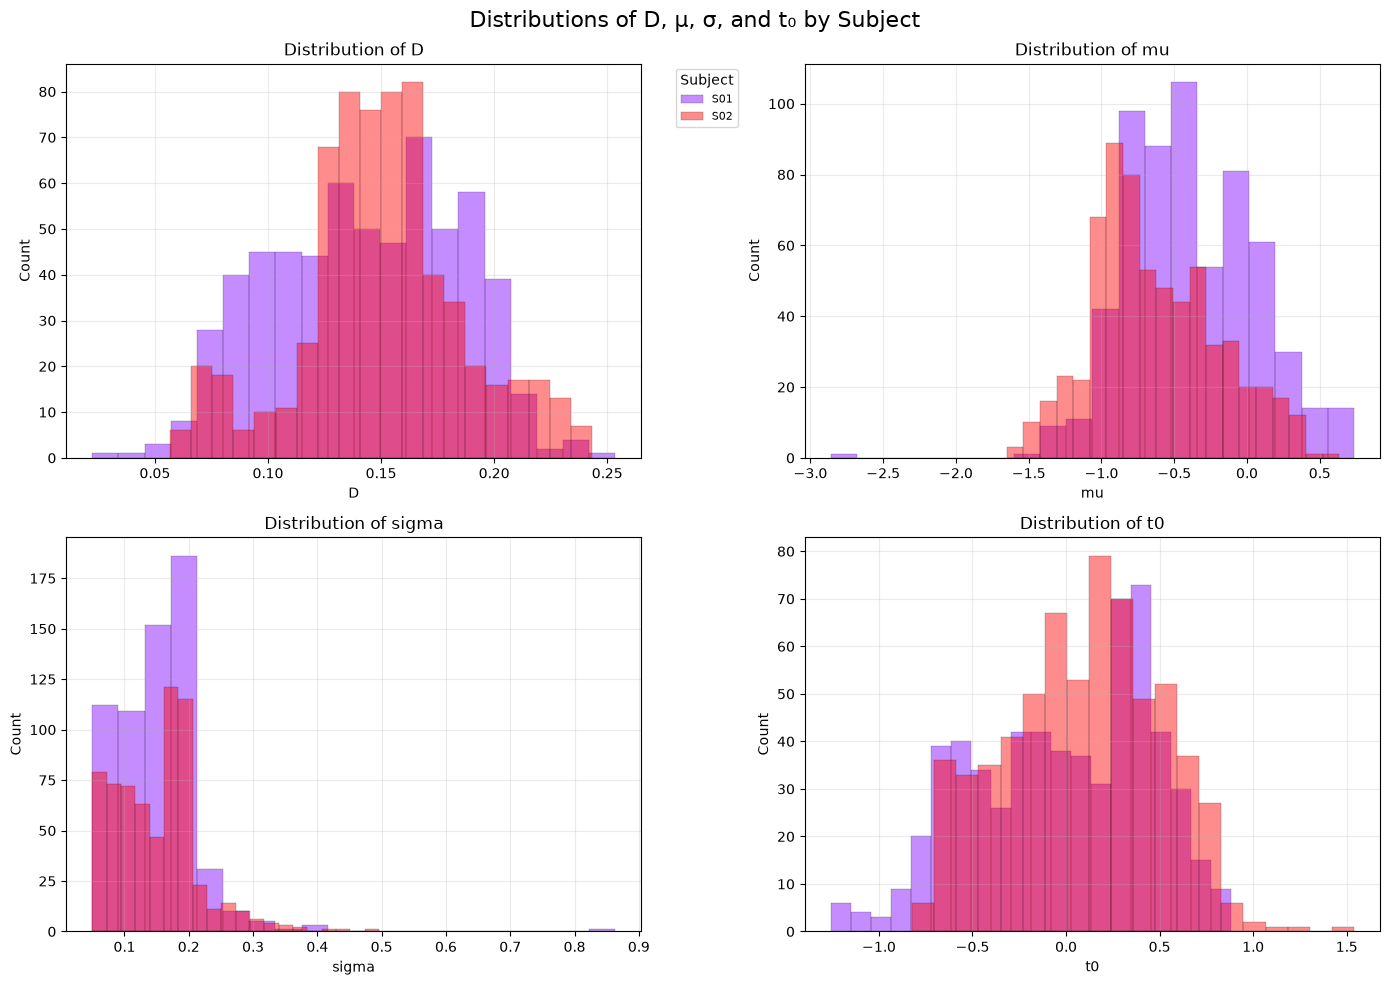

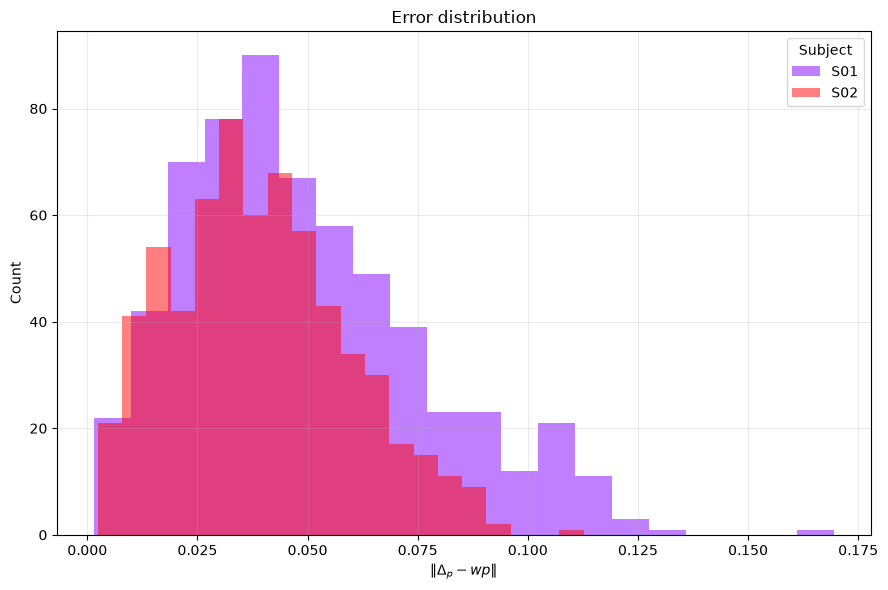

||delta_p - wp|| / ||wp||: median 0.322 | 90th pct 0.660


In [14]:
# Use the processed database and compute D from delta_p when it is not already available.
plot_data = final_database.copy()

if "D" not in plot_data.columns:
  plot_data["D"] = plot_data["delta_p"].apply(
    lambda v: np.linalg.norm(np.asarray(v, dtype=np.float32))
  )

metrics = ["D", "mu", "sigma", "t0"]
subjects = sorted(plot_data["subject"].dropna().unique())
colors = plt.cm.rainbow(np.linspace(0, 1, len(subjects)))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for ax, metric in zip(axes, metrics):
  for subject, color in zip(subjects, colors):
    values = plot_data.loc[
      plot_data["subject"] == subject, metric
    ].dropna()

    ax.hist(
      values,
      bins=20,
      alpha=0.45,
      color=color,
      label=subject,
      edgecolor="black",
      linewidth=0.3,
    )

  ax.set_title(f"Distribution of {metric}")
  ax.set_xlabel(metric)
  ax.set_ylabel("Count")
  ax.grid(alpha=0.25)

axes[0].legend(
  title="Subject",
  bbox_to_anchor=(1.05, 1),
  loc="upper left",
  fontsize=8,
)

fig.suptitle("Distributions of D, μ, σ, and t₀ by Subject", fontsize=16)
plt.tight_layout()
plt.show()

plot_data["delta_p_wp_distance"] = plot_data.apply(
  lambda row: np.linalg.norm(
    np.asarray(row["delta_p"], dtype=np.float32)
    - np.asarray(row["wp"], dtype=np.float32)
  ),
  axis=1,
)

plt.figure(figsize=(9, 6))
for subject, color in zip(subjects, colors):
  values = plot_data.loc[
    plot_data["subject"] == subject, "delta_p_wp_distance"
  ].dropna()
  plt.hist(values, bins=20, alpha=0.5, color=color, label=subject)

plt.title("Error distribution")
plt.xlabel(r"$\|\Delta_p - wp\|$")
plt.ylabel("Count")
plt.grid(alpha=0.25)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()


# sanity check of the geometry on the real data: endpoint error relative to the waypoint distance
wp_norm = plot_data["wp"].apply(np.linalg.norm)
rel_error = plot_data["delta_p_wp_distance"] / wp_norm.clip(lower=1e-9)
print(f"||delta_p - wp|| / ||wp||: median {rel_error.median():.3f} | 90th pct {rel_error.quantile(0.9):.3f}")

In [15]:
def prev_vector(series, dim):
    """Previous-stroke column -> list of float32 arrays; strokes without a predecessor get zeros
    (they are masked anyway and flagged by `is_first`)."""
    out = []
    for v in series:
        missing = v is None or (isinstance(v, float) and np.isnan(v))
        out.append(np.zeros(dim, dtype=np.float32) if missing else np.asarray(v, dtype=np.float32).reshape(dim))
    return out


data = final_database.copy()

formatted_data = pd.DataFrame({
    "subject": data["subject"].to_numpy(),
    "task": data["task"].to_numpy(),
    "stroke_number": data["stroke_number"].to_numpy(),
    "is_first": (data["stroke_number"] == 0).to_numpy().astype(np.float32),

    # conditioning: waypoint vectors in the stroke frame (start = origin)
    "wp": data["wp"],
    "wp_n": data["wp_n"],

    # network targets (delta_p is also a target: the stroke starts at zero and has to reach it)
    "t0": data["t0"].to_numpy(),
    "mu": data["mu"].to_numpy(),
    "sigma": data["sigma"].to_numpy(),
    "lambda_e": data["lambda_e"].to_numpy(),
    "u_e": data["u_e"],
    "delta_p": data["delta_p"],

    # start tangent: used ONLY by the small initial-tangent model (first stroke of a recording)
    "u_s": data["u_s"],
    "lambda_s": data["lambda_s"].to_numpy(),

    # previous stroke: same quantities as the outputs, WITHOUT delta_p
    "prev_t0": prev_vector(data["t0_previous"], 1),
    "prev_mu": prev_vector(data["mu_previous"], 1),
    "prev_sigma": prev_vector(data["sigma_previous"], 1),
    "prev_lambda_e": prev_vector(data["lambda_e_previous"], 1),
    "prev_u_e": prev_vector(data["u_e_previous"], 3),
})

formatted_data.head(10)

,subject,task,stroke_number,is_first,wp,wp_n,t0,mu,sigma,lambda_e,u_e,delta_p,u_s,lambda_s,prev_t0,prev_mu,prev_sigma,prev_lambda_e,prev_u_e
0,S01,BURSTc_XY,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",-0.642,0.153586,0.081711,0.060210,"(0.2207562287564279, 0.9723969202238582, 0.075...","(0.14432144911670713, 0.06706838777927969, -0....","(0.9700483590091524, -0.2362519799379216, -0.0...",0.033370,[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]"
1,S01,BURSTc_XY,1,0.0,"[-0.14432146, 0.010931612, 0.012907238]","[-0.14432146, 0.010931612, 0.012907238]",0.294,-0.680848,0.182883,0.028732,"(-0.9995785545264549, -0.02794476200820617, -0...","(-0.1601478798257494, 0.08058505759973233, 0.0...","(-0.11884807041176297, 0.9879203984706839, 0.0...",0.068837,[-0.642],[0.1535858],[0.08171056],[0.060209896],"[0.22075623, 0.9723969, 0.075570606]"
2,S01,BURSTc_XY,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",-0.240,-0.295600,0.138464,0.066373,"(0.2871657581466427, 0.9575315413899897, 0.025...","(0.17056932130531882, 0.060494883362214404, -0...","(0.9847971472621677, -0.14958862537256923, 0.0...",0.026934,[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]"
3,S01,BURSTc_XY,1,0.0,"[-0.17056932, 0.017505117, 0.0053005563]","[-0.17056932, 0.017505117, 0.0053005563]",0.254,-0.580980,0.181585,0.058829,"(-0.9705440395631034, -0.14308890984005446, 0....","(-0.1849465689957268, 0.08243738313551789, -0....","(-0.08052890672792198, 0.9967437579898101, 0.0...",0.067422,[-0.24],[-0.29560012],[0.13846438],[0.06637271],"[0.28716576, 0.9575315, 0.025868408]"
4,S01,BURSTc_XY,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",-0.618,0.107258,0.089652,0.060777,"(0.19773841109482437, 0.9793110041111769, 0.04...","(0.14651876924533025, 0.06354141825907234, -0....","(0.9240205645838965, -0.3809984546984475, -0.0...",0.039859,[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]"
5,S01,BURSTc_XY,1,0.0,"[-0.14651877, 0.014458582, 0.013137617]","[-0.14651877, 0.014458582, 0.013137617]",0.258,-0.637087,0.184532,0.047799,"(-0.9911391905463522, -0.12794444918787315, 0....","(-0.16339250686681103, 0.08152290983928898, -0...","(-0.1330558245604108, 0.9899640491792803, 0.04...",0.063654,[-0.618],[0.10725768],[0.08965201],[0.060777422],"[0.19773841, 0.979311, 0.04300556]"
6,S01,BURSTc_XY,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",-0.180,-0.179336,0.150746,0.102007,"(-0.20467495764630866, 0.9723170004232107, 0.1...","(0.1635246554743523, 0.09110137377997211, 0.00...","(0.9644672797467375, -0.24413089289483317, 0.1...",0.040779,[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]"
7,S01,BURSTc_XY,1,0.0,"[-0.16352466, -0.013101374, -0.0073017725]","[-0.16352466, -0.013101374, -0.0073017725]",0.488,-0.748430,0.200368,0.001607,"(-0.9827653840344551, -0.08492501585803988, -0...","(-0.16491086080623596, 0.05145149352032921, -0...","(-0.41841362029017637, 0.9057304711246873, 0.0...",0.076566,[-0.18],[-0.17933552],[0.15074614],[0.10200736],"[-0.20467496, 0.972317, 0.11272893]"
8,S01,BURSTc_XY,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",-0.510,-0.122554,0.117714,0.055750,"(0.3297911552546242, 0.9402459457217266, -0.08...","(0.15131736303067078, 0.051101890107903565, -0...","(0.9321635574676818, -0.3620058286494098, 0.00...",0.037631,[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]"
9,S01,BURSTc_XY,1,0.0,"[-0.15131736, 0.02689811, 0.012890997]","[-0.15131736, 0.02689811, 0.012890997]",0.118,-0.534845,0.175022,0.054437,"(-0.9427949527801668, -0.30160486974351186, 0....","(-0.18824215773834907, 0.07496334151829634, -0...","(-0.1376421086725083, 0.9816918142346144, -0.1...",0.067380,[-0.51],[-0.12255428],[0.117714435],[0.05574987],"[0.32979116, 0.9402459, -0.08470747]"


## Training

In [ ]:
# ---- split by subject ----
subjects = formatted_data["subject"].unique()
rng = np.random.default_rng(0)
rng.shuffle(subjects)
val_subjects = set(subjects[: max(1, int(0.15 * len(subjects)))])
is_val = formatted_data["subject"].isin(val_subjects)

train_df = formatted_data[~is_val].reset_index(drop=True)
val_df = formatted_data[is_val].reset_index(drop=True)
train_ds, val_ds = StrokeDataset(train_df), StrokeDataset(val_df)
train_loader = StrokeDataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = StrokeDataLoader(val_ds, batch_size=32, shuffle=False)
print(f"train strokes: {len(train_ds)} | val strokes: {len(val_ds)} | val subjects: {sorted(val_subjects)}")


# ---- standardization ----
@torch.no_grad()
def compute_stats(dataset, eps=1e-8):
    """(mean, std) per key, from a StrokeDataset.
    wp, wp_n and delta_p share ONE zero-mean isotropic scale: the stroke origin stays at 0, the three
    vectors stay in the same units and delta_p - wp keeps its geometric meaning (it is just rescaled)."""
    t = dataset.tensors
    stats = {k: (t[k].mean(0), t[k].std(0).clamp_min(eps)) for k in STAT_KEYS}
    pooled = torch.cat([t[k].reshape(-1) for k in GEOM_SHARED_KEYS])
    scale = pooled.pow(2).mean().sqrt().clamp_min(eps).item()
    for k in GEOM_SHARED_KEYS:
        d = t[k].size(1)
        stats[k] = (torch.zeros(d), torch.full((d,), scale))
    return stats


def _standardize(x, stat, device):
    m, s = stat
    x = x.float().to(device).reshape(x.size(0), -1)
    return (x - m.to(device)) / s.to(device)


def normalize_batch(batch, stats, device):
    """Standardize a batch (or a whole dataset dict) with the training statistics.
    prev_* reuse the statistics of the matching target and are zeroed for first strokes
    (no previous stroke): together with the `is_first` flag this is the start-of-sequence input."""
    is_first = batch["is_first"].float().to(device).reshape(-1, 1)
    out = {"is_first": is_first}
    for k in STAT_KEYS:
        out[k] = _standardize(batch[k], stats[k], device)
    for k in PREV_KEYS:
        out[k] = _standardize(batch[k], stats[k[len("prev_"):]], device) * (1.0 - is_first)
    return out


@torch.no_grad()
def stack_targets(dataset, stats):
    nb = normalize_batch(dataset.tensors, stats, "cpu")
    return torch.cat([nb[k] for k in TARGET_KEYS], dim=-1)


stats = compute_stats(train_ds)

# ---- model ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
INPUT_DIM = 2 * train_ds.tensors["wp"].size(1) + 1                     # wp, wp_n, is_first
OUTPUT_DIM = sum(train_ds.tensors[k].size(1) for k in TARGET_KEYS)     # t0, mu, sigma, lambda_e, u_e, delta_p
RECUR_DIM = sum(train_ds.tensors[k].size(1) for k in PREV_KEYS)        # same without delta_p
print(f"input {INPUT_DIM} | output {OUTPUT_DIM} | previous-stroke {RECUR_DIM}")
EMBEDDING_DIM = 32
MIXTURE_COMPONENTS = 16
LSTDM_DIM = 128
LSTM_COUNT = 2

MODEL = GenerativeModel(
    input_dim=INPUT_DIM, embedding_dim=EMBEDDING_DIM, LSTM_dim=LSTDM_DIM, LSTM_count=LSTM_COUNT,
    output_dim=OUTPUT_DIM, mixture_components=MIXTURE_COMPONENTS, recur_dim=RECUR_DIM,
).to(device)
MODEL.set_weights(stack_targets(train_ds, stats).to(device))

train strokes: 646 | val strokes: 610 | val subjects: ['S01']
input 7 | output 10 | previous-stroke 7


/tmp/ipykernel_61888/1174970033.py:4: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(subjects)
